In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [3]:
data = torch.load("embeddings.pth", map_location="cpu")

X_train = data["train"]["embeddings"].float()
y_train = data["train"]["labels"].squeeze().long()

X_val   = data["val"]["embeddings"].float()
y_val   = data["val"]["labels"].squeeze().long()

X_test  = data["test"]["embeddings"].float()
y_test  = data["test"]["labels"].squeeze().long()

print("Train shape:", X_train.shape)
print("Val shape:", X_val.shape)
print("Test shape:", X_test.shape)


C:\Users\Acer\AppData\Local\Temp\ipykernel_17000\1309241332.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  data = torch.load("embeddings.pth", map_location="cpu")


Train shape: torch.Size([89996, 512])
Val shape: torch.Size([10004, 512])
Test shape: torch.Size([7180, 512])


In [4]:
batch_size = 128

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, y_val), batch_size=batch_size)
test_loader  = DataLoader(TensorDataset(X_test, y_test), batch_size=batch_size)


In [5]:
num_classes = len(torch.unique(y_train))

model = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, num_classes)
).to(device)

print(model)


Sequential(
  (0): Linear(in_features=512, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=9, bias=True)
)


In [6]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=3e-4, weight_decay=1e-4)


In [7]:
def run_epoch(model, loader, train=False):
    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0
    all_preds = []
    all_labels = []

    with torch.set_grad_enabled(train):
        for X, y in loader:
            X = X.to(device)
            y = y.to(device)

            outputs = model(X)
            loss = criterion(outputs, y)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    avg_loss = total_loss / len(loader)

    return avg_loss, acc


In [24]:
import time

epochs = 30
history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

start_time = time.time()

for epoch in range(1, epochs + 1):

    tr_loss, tr_acc = run_epoch(model, train_loader, train=True)
    val_loss, val_acc = run_epoch(model, val_loader)

    # Store everything
    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch [{epoch}/{epochs}] "
          f"Train Loss: {tr_loss:.4f} | Train Acc: {tr_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc*100:.2f}%")

total_time = time.time() - start_time
print(f"\nTotal Training Time: {total_time:.2f} seconds")

Epoch [1/30] Train Loss: 0.2530 | Train Acc: 92.04% | Val Loss: 0.2290 | Val Acc: 93.08%
Epoch [2/30] Train Loss: 0.2534 | Train Acc: 92.05% | Val Loss: 0.2306 | Val Acc: 93.12%
Epoch [3/30] Train Loss: 0.2509 | Train Acc: 92.14% | Val Loss: 0.2309 | Val Acc: 92.87%
Epoch [4/30] Train Loss: 0.2524 | Train Acc: 92.02% | Val Loss: 0.2283 | Val Acc: 93.07%
Epoch [5/30] Train Loss: 0.2504 | Train Acc: 92.20% | Val Loss: 0.2289 | Val Acc: 93.00%
Epoch [6/30] Train Loss: 0.2513 | Train Acc: 92.05% | Val Loss: 0.2285 | Val Acc: 93.05%
Epoch [7/30] Train Loss: 0.2506 | Train Acc: 92.09% | Val Loss: 0.2284 | Val Acc: 92.98%
Epoch [8/30] Train Loss: 0.2501 | Train Acc: 92.12% | Val Loss: 0.2328 | Val Acc: 92.70%
Epoch [9/30] Train Loss: 0.2501 | Train Acc: 92.11% | Val Loss: 0.2297 | Val Acc: 92.91%
Epoch [10/30] Train Loss: 0.2503 | Train Acc: 92.15% | Val Loss: 0.2274 | Val Acc: 93.20%
Epoch [11/30] Train Loss: 0.2484 | Train Acc: 92.24% | Val Loss: 0.2294 | Val Acc: 92.90%
Epoch [12/30] Train

In [25]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)
        outputs = model(X)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.numpy())

test_accuracy = accuracy_score(all_labels, all_preds)
precision = precision_score(all_labels, all_preds, average="macro")
recall = recall_score(all_labels, all_preds, average="macro")
f1 = f1_score(all_labels, all_preds, average="macro")

print("\n===== TEST RESULTS =====")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")
print(f"Precision (Macro): {precision:.4f}")
print(f"Recall (Macro): {recall:.4f}")
print(f"F1 Score (Macro): {f1:.4f}")



===== TEST RESULTS =====
Test Accuracy: 89.76%
Precision (Macro): 0.8597
Recall (Macro): 0.8643
F1 Score (Macro): 0.8602


In [26]:
cm = confusion_matrix(all_labels, all_preds)
class_acc = cm.diagonal() / cm.sum(axis=1)

for i, acc in enumerate(class_acc):
    print(f"Class {i} Accuracy: {acc*100:.2f}%")


Class 0 Accuracy: 98.51%
Class 1 Accuracy: 99.76%
Class 2 Accuracy: 84.37%
Class 3 Accuracy: 97.16%
Class 4 Accuracy: 93.91%
Class 5 Accuracy: 75.84%
Class 6 Accuracy: 85.43%
Class 7 Accuracy: 53.68%
Class 8 Accuracy: 89.21%


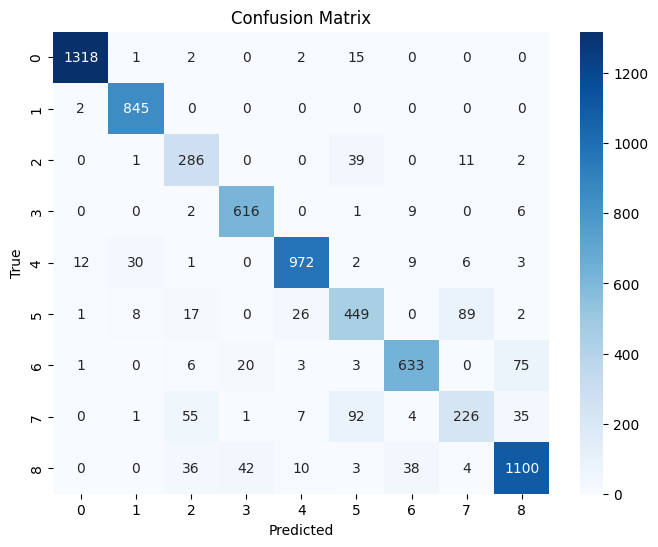

In [27]:
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()


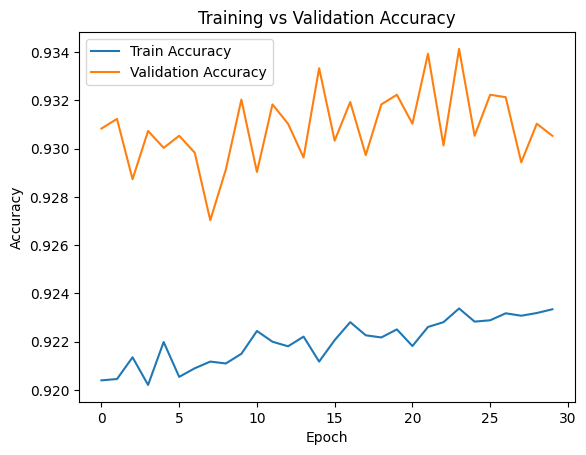

In [28]:
plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")
plt.legend()
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()


In [29]:
torch.save(model.state_dict(), "FrozenCLIP_2LayerMLP.pth")

with open("FrozenCLIP_2LayerMLP_test_accuracy.txt", "w") as f:
    f.write(f"Test Accuracy: {test_accuracy*100:.2f}%\n")

print("Model and accuracy saved.")


Model and accuracy saved.


In [30]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_preds)

class_acc = cm.diagonal() / cm.sum(axis=1)

for i, acc in enumerate(class_acc):
    print(f"Class {i} Accuracy: {acc*100:.2f}%")


Class 0 Accuracy: 98.51%
Class 1 Accuracy: 99.76%
Class 2 Accuracy: 84.37%
Class 3 Accuracy: 97.16%
Class 4 Accuracy: 93.91%
Class 5 Accuracy: 75.84%
Class 6 Accuracy: 85.43%
Class 7 Accuracy: 53.68%
Class 8 Accuracy: 89.21%


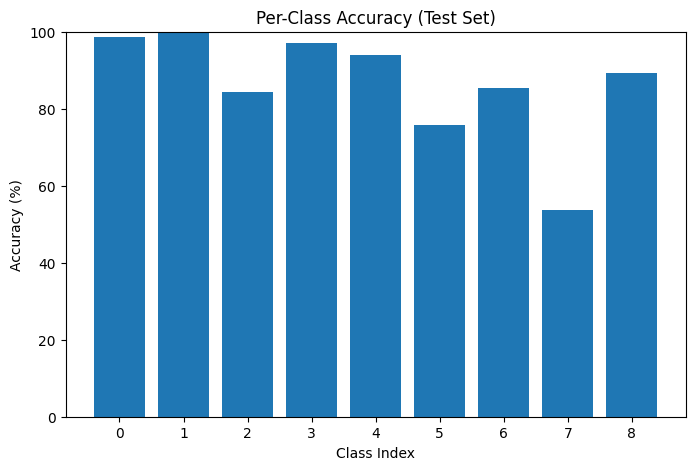

In [31]:
plt.figure(figsize=(8,5))
plt.bar(range(len(class_acc)), class_acc * 100)
plt.xlabel("Class Index")
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy (Test Set)")
plt.xticks(range(len(class_acc)))
plt.ylim(0,100)
plt.show()


In [32]:
final_train = history["train_acc"][-1] * 100
final_val   = history["val_acc"][-1] * 100
final_test  = test_accuracy * 100

print(f"Final Train Accuracy: {final_train:.2f}%")
print(f"Final Validation Accuracy: {final_val:.2f}%")
print(f"Final Test Accuracy: {final_test:.2f}%")

print(f"Train - Val Gap: {final_train - final_val:.2f}%")
print(f"Val - Test Gap: {final_val - final_test:.2f}%")


Final Train Accuracy: 92.33%
Final Validation Accuracy: 93.05%
Final Test Accuracy: 89.76%
Train - Val Gap: -0.72%
Val - Test Gap: 3.29%


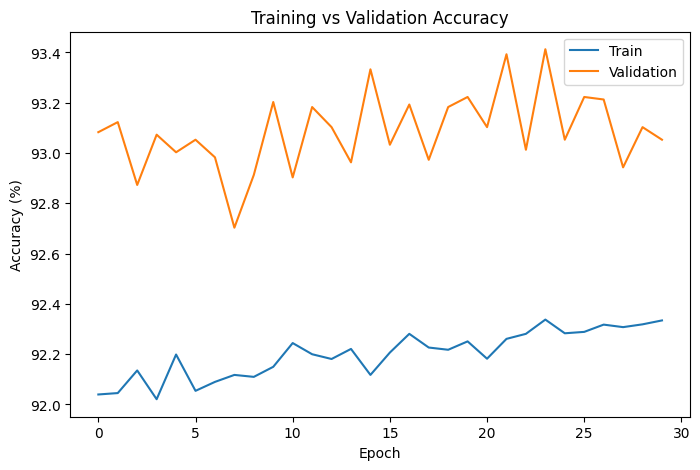

In [33]:
plt.figure(figsize=(8,5))
plt.plot(np.array(history["train_acc"])*100, label="Train")
plt.plot(np.array(history["val_acc"])*100, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()


In [34]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

# Convert to numpy (just to be safe)
y_true = np.array(all_labels)
y_pred = np.array(all_preds)

# Generate full classification report
report_dict = classification_report(y_true, y_pred, output_dict=True)

# Convert to DataFrame
report_df = pd.DataFrame(report_dict).transpose()

print("\n===== CLASSIFICATION REPORT =====")
print(report_df)


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score      support
0              0.988006  0.985052  0.986527  1338.000000
1              0.953725  0.997639  0.975188   847.000000
2              0.706173  0.843658  0.768817   339.000000
3              0.907216  0.971609  0.938309   634.000000
4              0.952941  0.939130  0.945985  1035.000000
5              0.743377  0.758446  0.750836   592.000000
6              0.913420  0.854251  0.882845   741.000000
7              0.672619  0.536817  0.597094   421.000000
8              0.899428  0.892133  0.895765  1233.000000
accuracy       0.897632  0.897632  0.897632     0.897632
macro avg      0.859656  0.864304  0.860152  7180.000000
weighted avg   0.896895  0.897632  0.896255  7180.000000


In [41]:
from sklearn.metrics import classification_report

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(all_labels, all_preds, labels=list(range(9)), digits=4))


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0     0.9880    0.9851    0.9865      1338
           1     0.9537    0.9976    0.9752       847
           2     0.7062    0.8437    0.7688       339
           3     0.9072    0.9716    0.9383       634
           4     0.9529    0.9391    0.9460      1035
           5     0.7434    0.7584    0.7508       592
           6     0.9134    0.8543    0.8828       741
           7     0.6726    0.5368    0.5971       421
           8     0.8994    0.8921    0.8958      1233

    accuracy                         0.8976      7180
   macro avg     0.8597    0.8643    0.8602      7180
weighted avg     0.8969    0.8976    0.8963      7180



In [37]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
import numpy as np
import pandas as pd

y_true = np.array(all_labels)
y_pred = np.array(all_preds)

labels = list(range(9))

# Per-class metrics (raw values)
precision = precision_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
recall    = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
f1        = f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0)

# SUPPORT as INTEGER (this is what you wanted)
support = np.bincount(y_true, minlength=len(labels)).astype(int)

# Build table
report_df = pd.DataFrame({
    "precision": precision,
    "recall": recall,
    "f1-score": f1,
    "support": support
})

# Exact accuracy
acc = accuracy_score(y_true, y_pred)

# Averages
macro_avg = report_df[["precision", "recall", "f1-score"]].mean()

weighted_avg = np.average(
    report_df[["precision", "recall", "f1-score"]],
    weights=support,
    axis=0
)

# Add summary rows (support stays integer)
report_df.loc["accuracy"] = [acc, acc, acc, int(len(y_true))]
report_df.loc["macro avg"] = [macro_avg[0], macro_avg[1], macro_avg[2], int(support.sum())]
report_df.loc["weighted avg"] = [weighted_avg[0], weighted_avg[1], weighted_avg[2], int(support.sum())]

print("\n===== CLASSIFICATION REPORT  =====")
print(report_df)


===== CLASSIFICATION REPORT  =====
              precision    recall  f1-score  support
0              0.988006  0.985052  0.986527   1338.0
1              0.953725  0.997639  0.975188    847.0
2              0.706173  0.843658  0.768817    339.0
3              0.907216  0.971609  0.938309    634.0
4              0.952941  0.939130  0.945985   1035.0
5              0.743377  0.758446  0.750836    592.0
6              0.913420  0.854251  0.882845    741.0
7              0.672619  0.536817  0.597094    421.0
8              0.899428  0.892133  0.895765   1233.0
accuracy       0.897632  0.897632  0.897632   7180.0
macro avg      0.859656  0.864304  0.860152   7180.0
weighted avg   0.896895  0.897632  0.896255   7180.0


C:\Users\Acer\AppData\Local\Temp\ipykernel_17000\4232282307.py:40: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  report_df.loc["macro avg"] = [macro_avg[0], macro_avg[1], macro_avg[2], int(support.sum())]


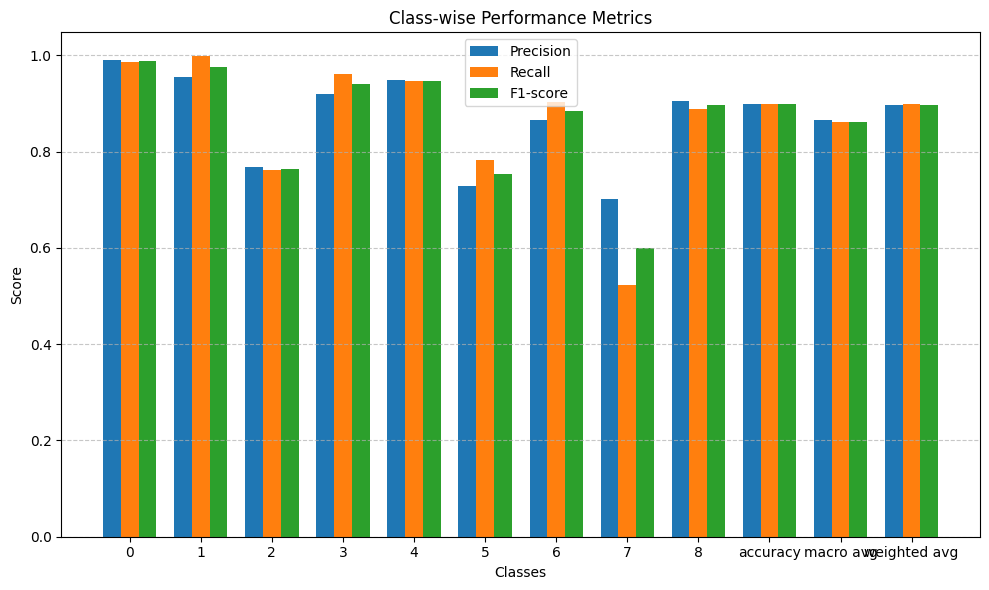

In [23]:
import numpy as np
import matplotlib.pyplot as plt

classes = report_df.index.astype(str)

precision = report_df["precision"].values
recall = report_df["recall"].values
f1 = report_df["f1-score"].values

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(10,6))

plt.bar(x - width, precision, width, label="Precision")
plt.bar(x, recall, width, label="Recall")
plt.bar(x + width, f1, width, label="F1-score")

plt.xticks(x, classes)
plt.xlabel("Classes")
plt.ylabel("Score")
plt.title("Class-wise Performance Metrics")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [22]:
mis_idx = np.where(y_true != y_pred)[0]
print(f"\nTotal Misclassified Samples: {len(mis_idx)}")


Total Misclassified Samples: 759


In [23]:
from collections import Counter

errors = [(t, p) for t, p in zip(y_true, y_pred) if t != p]
error_counts = Counter(errors)

print("\nMost frequent misclassifications:")
for (true, pred), count in error_counts.most_common(10):
    print(f"True {true} → Pred {pred}: {count}")


Most frequent misclassifications:
True 6 → Pred 8: 97
True 5 → Pred 7: 91
True 7 → Pred 5: 91
True 2 → Pred 5: 74
True 7 → Pred 8: 48
True 7 → Pred 2: 41
True 8 → Pred 3: 31
True 8 → Pred 6: 29
True 4 → Pred 1: 27
True 5 → Pred 4: 26


In [24]:
import json
import numpy as np

def to_python(obj):
    """Convert numpy / torch / weird types into JSON-safe Python types"""
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.float32, np.float64, np.floating)):
        return float(obj)
    if isinstance(obj, (np.int32, np.int64, np.integer)):
        return int(obj)
    return obj

# ----------------------------
# SAFELY ENSURE SCALAR METRICS
# ----------------------------
test_accuracy = float(test_accuracy)
precision = float(np.array(precision).item()) if np.ndim(precision) == 0 else float(np.mean(precision))
recall = float(np.array(recall).item()) if np.ndim(recall) == 0 else float(np.mean(recall))
f1 = float(np.array(f1).item()) if np.ndim(f1) == 0 else float(np.mean(f1))

final_train = float(final_train)
final_val = float(final_val)
final_test = float(final_test)

# ----------------------------
# CONFUSION MATRIX
# ----------------------------
cm_list = cm.tolist()

# ----------------------------
# CLASS METRICS
# ----------------------------
class_metrics = {
    "class_accuracy": class_acc.tolist()
}

# ----------------------------
# CLASSIFICATION REPORT
# ----------------------------
report_json = report_df.to_dict()

# ----------------------------
# FINAL EXPERIMENT STRUCTURE
# ----------------------------
experiment_data = {
    "history": {
        "train_loss": history["train_loss"],
        "train_acc": history["train_acc"],
        "val_loss": history["val_loss"],
        "val_acc": history["val_acc"]
    },

    "final_metrics": {
        "train_acc": final_train,
        "val_acc": final_val,
        "test_acc": final_test,
        "train_val_gap": final_train - final_val,
        "val_test_gap": final_val - final_test
    },

    "test_metrics": {
        "accuracy": test_accuracy,
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1
    },

    "confusion_matrix": cm_list,
    "class_metrics": class_metrics,
    "classification_report": report_json
}

# ----------------------------
# SAVE JSON FILE
# ----------------------------
with open("experiment_results.json", "w") as f:
    json.dump(experiment_data, f, indent=4, default=to_python)

print("Saved experiment_results.json successfully.")


Saved experiment_results.json successfully.


In [25]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

model.eval()

y_score = []
y_true = []

with torch.no_grad():
    for X, y in test_loader:
        X = X.to(device)
        outputs = model(X)

        probs = torch.softmax(outputs, dim=1)  # IMPORTANT for ROC

        y_score.append(probs.cpu().numpy())
        y_true.append(y.cpu().numpy())

y_score = np.concatenate(y_score)
y_true = np.concatenate(y_true)

In [26]:
n_classes = y_score.shape[1]
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))

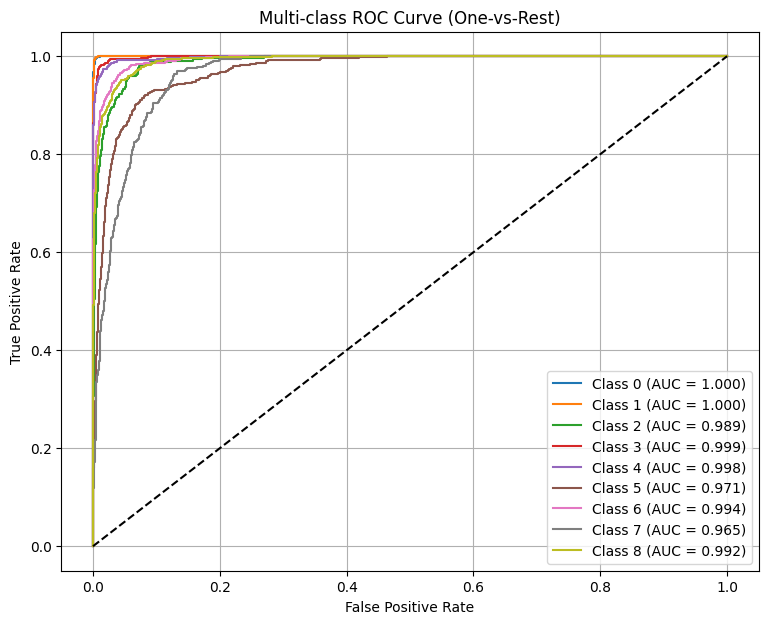

In [27]:
plt.figure(figsize=(9,7))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"Class {i} (AUC = {roc_auc:.3f})")

# random baseline
plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multi-class ROC Curve (One-vs-Rest)")
plt.legend()
plt.grid()
plt.show()

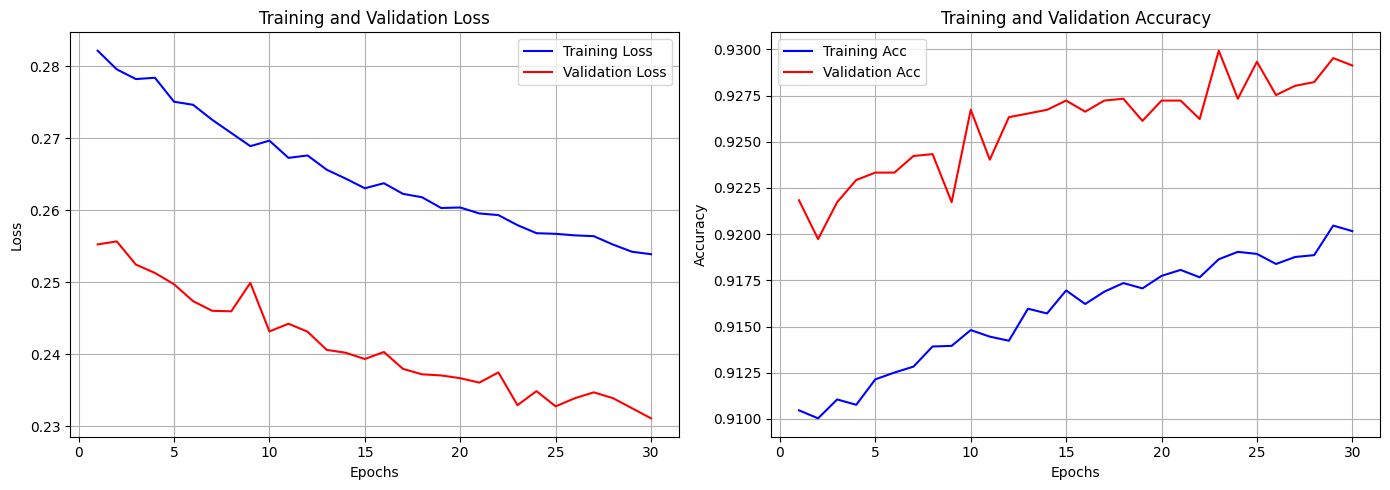

In [28]:
import matplotlib.pyplot as plt

# Extract data from your history dictionary
epochs = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(14, 5))

# Plot Training & Validation Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, history['train_loss'], 'b-', label='Training Loss')
plt.plot(epochs, history['val_loss'], 'r-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Training & Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, history['train_acc'], 'b-', label='Training Acc')
plt.plot(epochs, history['val_acc'], 'r-', label='Validation Acc')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [29]:
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# 1. Calculate Per-Class Metrics from your test results
# Assumes 'all_labels' and 'all_preds' are from your test set evaluation
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average=None)

# 2. Create the DataFrame
metrics_df = pd.DataFrame({
    'Class': [f'Class {i}' for i in range(len(precision))],
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1
})

# 3. Add Global Accuracies (pulling from your 'history' and 'test_accuracy' variable)
global_metrics = pd.DataFrame([
    {'Class': '--- GLOBAL ---', 'Precision': None, 'Recall': None, 'F1 Score': None},
    {'Class': 'Train Accuracy', 'Precision': history['train_acc'][-1], 'Recall': None, 'F1 Score': None},
    {'Class': 'Val Accuracy', 'Precision': history['val_acc'][-1], 'Recall': None, 'F1 Score': None},
    {'Class': 'Test Accuracy', 'Precision': test_accuracy, 'Recall': None, 'F1 Score': None}
])

final_table = pd.concat([metrics_df, global_metrics], ignore_index=True)

# Format for readability
print(final_table.to_string(index=False, justify='center', float_format=lambda x: f"{x:.4f}" if pd.notnull(x) else "-"))

    Class       Precision  Recall  F1 Score
       Class 0   0.9881    0.9888   0.9884 
       Class 1   0.9548    0.9976   0.9758 
       Class 2   0.7484    0.7109   0.7292 
       Class 3   0.9266    0.9558   0.9410 
       Class 4   0.9451    0.9478   0.9465 
       Class 5   0.7134    0.7652   0.7384 
       Class 6   0.9316    0.8273   0.8763 
       Class 7   0.6589    0.5368   0.5916 
       Class 8   0.8675    0.9189   0.8925 
--- GLOBAL ---      NaN       NaN      NaN 
Train Accuracy   0.9202       NaN      NaN 
  Val Accuracy   0.9291       NaN      NaN 
 Test Accuracy   0.8943       NaN      NaN 


C:\Users\Acer\AppData\Local\Temp\ipykernel_14720\3164305795.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  final_table = pd.concat([metrics_df, global_metrics], ignore_index=True)


In [30]:
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# 1. Calculate Overall Test Metrics (Weighted Average)
# This uses your existing 'all_labels' and 'all_preds'
test_p, test_r, test_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
test_acc = accuracy_score(all_labels, all_preds)

# 2. Create the Summary Data
# Note: Train/Val usually only track Accuracy during the training loop
summary_data = {
    'Dataset': ['Train', 'Validation', 'Test'],
    'Accuracy': [history['train_acc'][-1], history['val_acc'][-1], test_acc],
    'Precision': [None, None, test_p],
    'Recall': [None, None, test_r],
    'F1 Score': [None, None, test_f1]
}

# 3. Create and Format DataFrame
summary_df = pd.DataFrame(summary_data)

print("--- OVERALL PERFORMANCE SUMMARY ---")
print(summary_df.to_string(index=False, justify='center', float_format=lambda x: f"{x:.4f}" if pd.notnull(x) else "-"))

--- OVERALL PERFORMANCE SUMMARY ---
 Dataset    Accuracy  Precision  Recall  F1 Score
     Train   0.9202       NaN       NaN      NaN 
Validation   0.9291       NaN       NaN      NaN 
      Test   0.8943    0.8927    0.8943   0.8925 


In [31]:
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# 1. Calculate Overall Test Metrics (Weighted Average)
# This uses your existing 'all_labels' and 'all_preds'
test_p, test_r, test_f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
test_acc = accuracy_score(all_labels, all_preds)

# 2. Create the Summary Data
# Note: Train/Val usually only track Accuracy during the training loop
summary_data = {
    'Dataset': ['Train', 'Validation', 'Test'],
    'Accuracy': [history['train_acc'][-1], history['val_acc'][-1], test_acc],
    'Precision': [None, None, test_p],
    'Recall': [None, None, test_r],
    'F1 Score': [None, None, test_f1]
}

# 3. Create and Format DataFrame
summary_df = pd.DataFrame(summary_data)

print("--- OVERALL PERFORMANCE SUMMARY ---")
print(summary_df.to_string(index=False, justify='center', float_format=lambda x: f"{x:.4f}" if pd.notnull(x) else "-"))

--- OVERALL PERFORMANCE SUMMARY ---
 Dataset    Accuracy  Precision  Recall  F1 Score
     Train   0.9202       NaN       NaN      NaN 
Validation   0.9291       NaN       NaN      NaN 
      Test   0.8943    0.8927    0.8943   0.8925 
